# DNAscape quickstart

This notebook introduces the two core DNAscape workflows: `rmap` and `rsim`.

`rmap` provides efficient mathematical shortcuts for mapping between replication features in specific, well-defined scenarios where one-to-one relationships are expected. Starting from experimental or model-derived inputs, it uses deterministic transformations under explicit mechanistic assumptions to rapidly fit and infer features such as origin activity, fork speed, replication timing, among others.

`rsim` provides a fuller mechanistic description of the replication process. Starting from origin firing and fork speed profiles under specific assumptions and optional model features, it simulates stochastic DNA replication directly. This makes it possible to explore broader scenarios, perform statistical analyses over many simulated S phases, and test hypotheses that go beyond the settings where closed-form or deterministic mapping shortcuts are available.

Below, we present a few short examples designed to give a brief introduction to DNAscape. Full details of both workflows, including how they interact, are provided in `2_mapping.ipynb` and `3_simulation.ipynb`.

## Setup

Use an environment where DNAscape is installed, or start Jupyter from the repository root after an editable install. Autoreload keeps the notebook responsive while the source code is being developed.


In [1]:
%reload_ext autoreload
%autoreload 2

from dnascape import *

## Load example data

We start from the hESC chromosome 1 replication-timing profile. The loaded profile is a one-dimensional array with one value per genomic bin, at a one kilobase resolution.


In [2]:
replication_timing_full = loadcsv(
    "example",
    example="replication_timing_hESC",
    chr_number=1,
)

To focus on a specific genomic region, we can use `select_profile_region` to evaluate `replication_timing_full` at a new set of genomic positions, `positions_kb`, defined at a desired resolution. By default, we assume the same resolution as the full chromosome dataset.

In [18]:
replication_timing, positions_kb = select_profile_region(
    replication_timing_full,
    interval_kb=(0, 60_000),
    output_resolution_kb=1,
)

A quick plot is useful before fitting. We may do that with `plotf`.

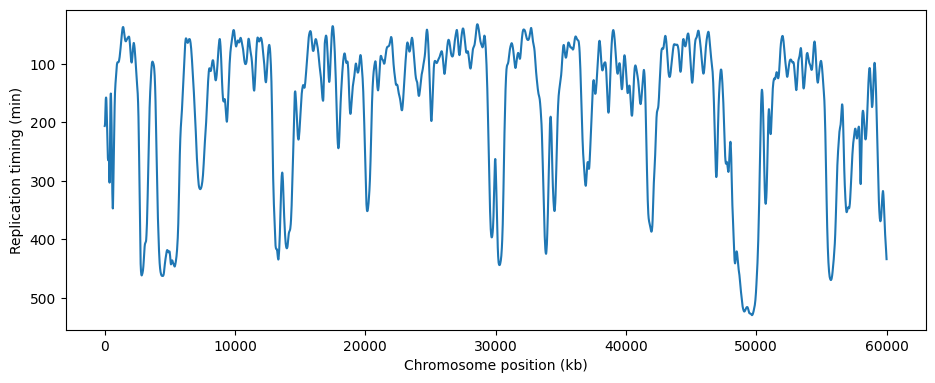

In [19]:
plotf(
    replication_timing,
    x_array=positions_kb,
    invyQ=True,
    xtitle="Chromosome position (kb)",
    ytitle="Replication timing (min)",
)

With the timing dataset loaded, we may now use it to map and simulate DNA replication features.

## A. Mapping replication features

`rmap` is the mapping interface. It takes a source feature, a target feature, and a dictionary of assumptions. Internally, DNAscape selects the appropriate route for the requested mapping.


### Fit origin firing rate from timing

Here we infer a space-dependent firing-rate profile, $I(x)$, from replication timing, assuming a constant fork speed.

In [20]:
fork_speed = 1.4  # kb/min

firing_rate = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
)

print(f"Fitted I(x) from replication timing data, assuming a constant fork speed of {fork_speed} kb/min.")

Fitted I(x) from replication timing data, assuming a constant fork speed of 1.4 kb/min.


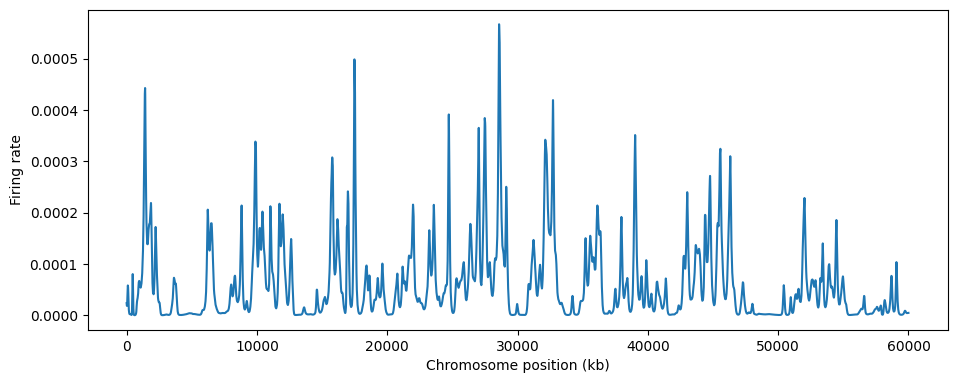

In [21]:
plotf(
    firing_rate,
    x_array=positions_kb,
    xtitle="Chromosome position (kb)",
    ytitle="Firing rate",
)

### Map the fitted profile back to timing

Forward-mapping the fitted firing rate profile back to timing gives a direct visual check of the mapping loop, this can later be compared with averaged stochastic simulations.


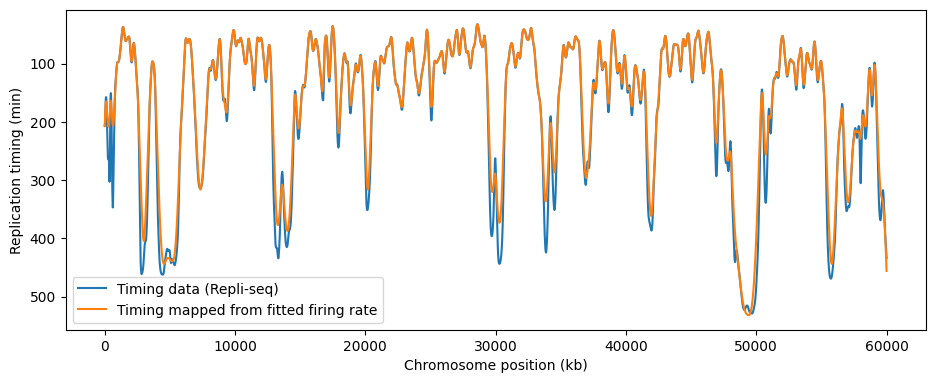

In [22]:
replication_timing_mapped = rmap(
    source={
        "firing_rate": firing_rate,
        "fork_speed": fork_speed,
    },
    target="replication_timing",
)

plotf(
    replication_timing,
    replication_timing_mapped,
    x_array=positions_kb,
    labels=["Timing data (Repli-seq)", "Timing mapped from fitted firing rate"],
    invyQ=True,
    xtitle="Chromosome position (kb)",
    ytitle="Replication timing (min)",
)

As expected, the fitting is not perfect, as the constant fork speed assumptions is too strong to describe the data. We may, for example, check a measure of the misfit by looking at their difference.

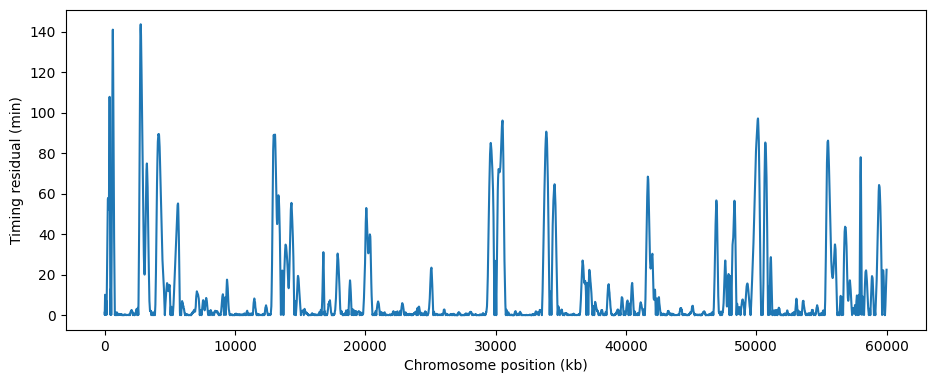

In [23]:
plotf(
    np.abs(replication_timing - replication_timing_mapped),
    x_array=positions_kb,
    xtitle="Chromosome position (kb)",
    ytitle="Timing residual (min)",
)

### Mapping fork speed from replication timing and firing rate

Conveniently, `rmap` also provides a tool to map fork speed along the chromosome, provided we have replication timing and origin firing data. By default, the mapping assumes fork speed varies only in space, but generalisations are possible (see `mapping.ipynb`).

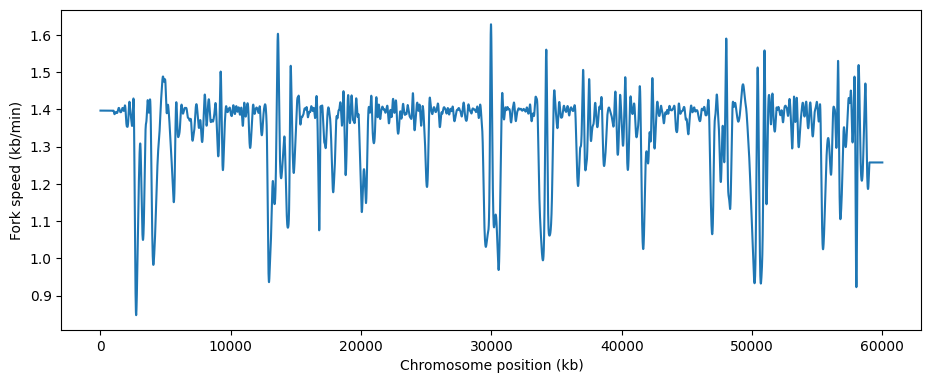

In [24]:
fork_speed_mapped = rmap(
    source={
        "firing_rate": firing_rate,
        "replication_timing": replication_timing,
    },
    target="fork_speed",
)

plotf(
    fork_speed_mapped,
    x_array=positions_kb,
    xtitle="Chromosome position (kb)",
    ytitle="Fork speed (kb/min)",
)

If we now forward-map the inferred firing rate together with the space-dependent fork speed to replication timing, and compare the resulting misfit with that obtained under a constant fork speed assumption, we observe a substantial improvement.

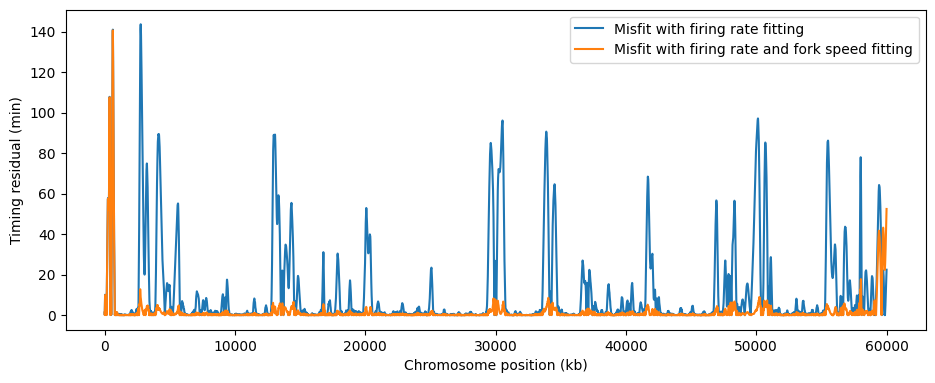

In [25]:
replication_timing_mapped_with_fork = rmap(
    source={
        "firing_rate": firing_rate,
        "fork_speed": fork_speed_mapped,
    },
    target="replication_timing",
)

plotf(
    np.abs(replication_timing - replication_timing_mapped),
    np.abs(replication_timing - replication_timing_mapped_with_fork),
    x_array=positions_kb,
    labels=["Misfit with firing rate fitting", "Misfit with firing rate and fork speed fitting"],
    xtitle="Chromosome position (kb)",
    ytitle="Timing residual (min)",
)

**Note.** DNAscape supports several modelling choices, but more constrained assumptions, such as constant fork speed, can provide a useful baseline, improve biological interpretability and reduce overfitting. Although allowing both $I(x,t)$ and $v(x,t)$ to vary in space and time can improve the fit to replication timing, the timing curve alone does not uniquely determine the pair $(I,v)$. Multiple firing-rate and fork-speed profiles may therefore explain the same data, making additional assumptions or complementary datasets essential for meaningful inference. For illustration purposes, we keep the examples below for space-dependent initiation rate and constant fork speed.

### Map timing to fork directionality

Replication fork directionality (RFD) is another feature of the replication programme, and can be obtained directly from replication timing and fork speed.

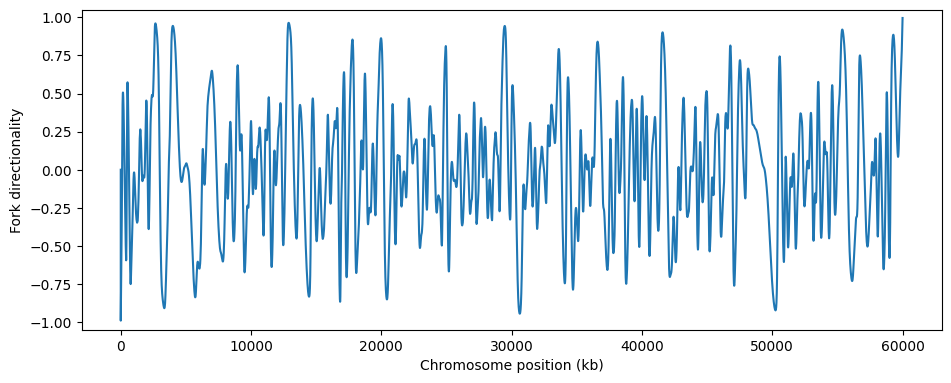

In [26]:
timing_reference = replication_timing_mapped

fork_directionality = rmap(
    source={
        "replication_timing": timing_reference,
        "fork_speed": fork_speed,
    },
    target="fork_directionality",
)

plotf(
    fork_directionality,
    x_array=positions_kb,
    xtitle="Chromosome position (kb)",
    ytitle="Fork directionality",
    ylims=(-1.05, 1.05),
)

## B. Simulating replication

In addition to mapping replication features under different assumptions, DNAscape can simulate replication directly. This provides a way to validate the mapping shortcuts introduced in the previous section, while also enabling the exploration of new scenarios and the testing of mechanistic hypotheses.

Replication simulations are performed using `rsim`, which generates replication dynamics from a supplied firing-rate profile, fork speed and optional model assumptions, such as fork stalling, limiting firing factors or periodic genome geometry. We present a few examples below; see `3_simulation.ipynb` for a fuller overview of the available options and properties.

### Simulate from the fitted firing rate

The simulation uses the fitted firing-rate profile from section A. `rsim` prints progress by default.


In [27]:
sim_number = 100

simulation = rsim(
    source={
        "firing_rate": firing_rate,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": sim_number,
        "time_statsQ": True,
    },
)

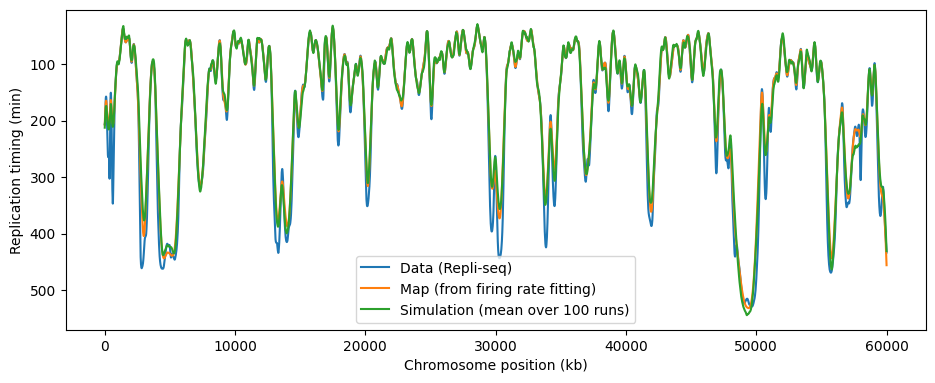

In [28]:
plotf(
    replication_timing,
    replication_timing_mapped,
    simulation["replication_timing"],
    x_array=positions_kb,
    labels=["Data (Repli-seq)", "Map (from firing rate fitting)", f"Simulation (mean over {sim_number} runs)"],
    invyQ=True,
    xtitle="Chromosome position (kb)",
    ytitle="Replication timing (min)",
)

### Inspect simulation outputs

The simulation returns genome-wide profiles, time courses, and per-simulation summaries. These plots show the replicated fraction over time, origin efficiency along the genome, inter-origin distances, and compact summary statistics.


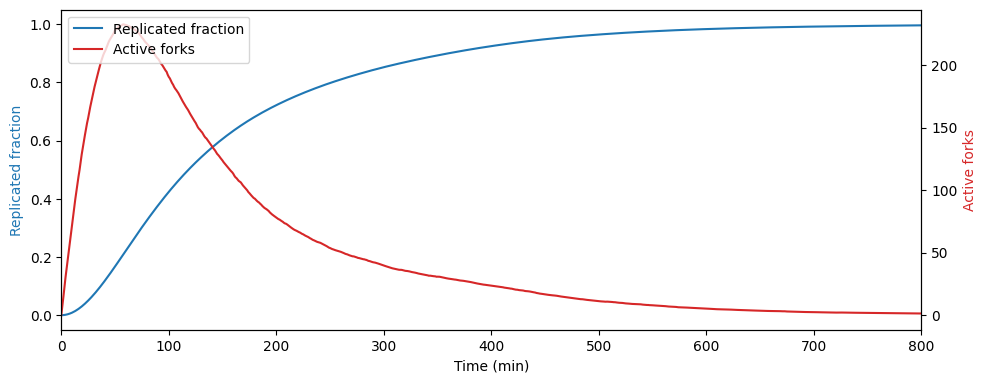

In [29]:
plotf(
    simulation["replicated_fraction"],
    simulation["active_forks"],
    labels=["Replicated fraction", "Active forks"],
    dual_axis=True,
    xtitle="Time (min)",
    xlims=(0, 800),
)

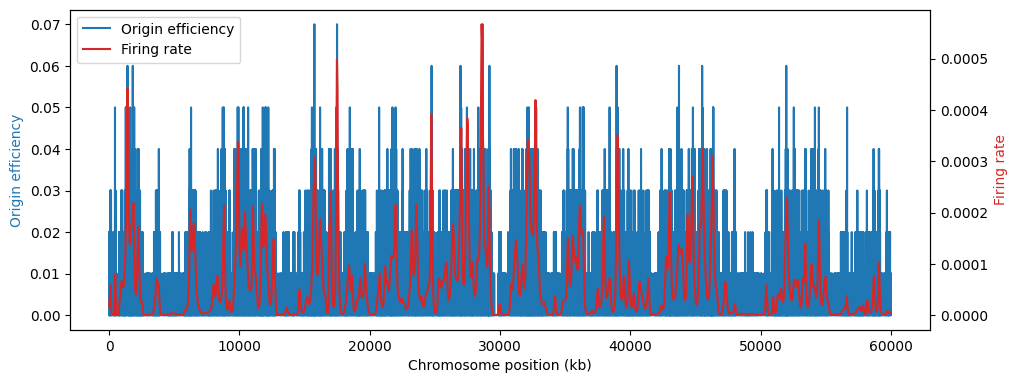

In [30]:
plotf(
    simulation["origin_efficiency"],
    firing_rate,
    x_array=positions_kb,
    labels=["Origin efficiency", "Firing rate"],
    dual_axis=True,
    xtitle="Chromosome position (kb)",
)

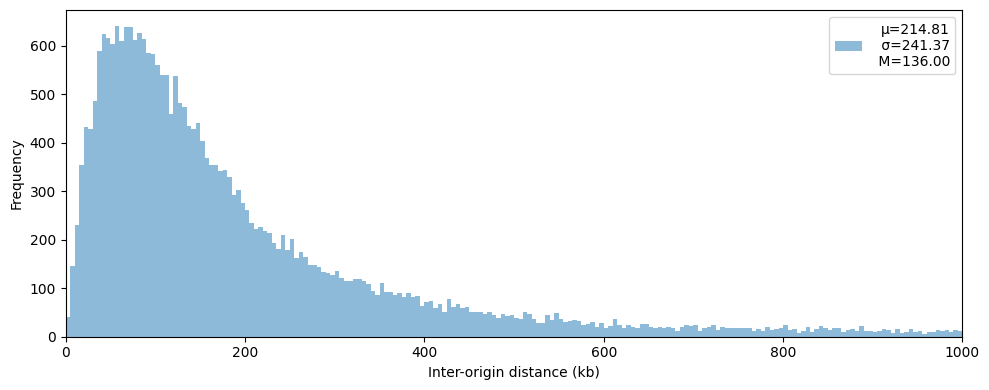

In [31]:
ploth(
    simulation["inter_origin_distance"],
    xtitle="Inter-origin distance (kb)",
    xmax=1000,
)

### Combined genomic view

`mplotf` stacks several genomic tracks into one figure. This is often the most compact way to compare the input data, fitted maps, and simulation-derived profiles over the same interval.


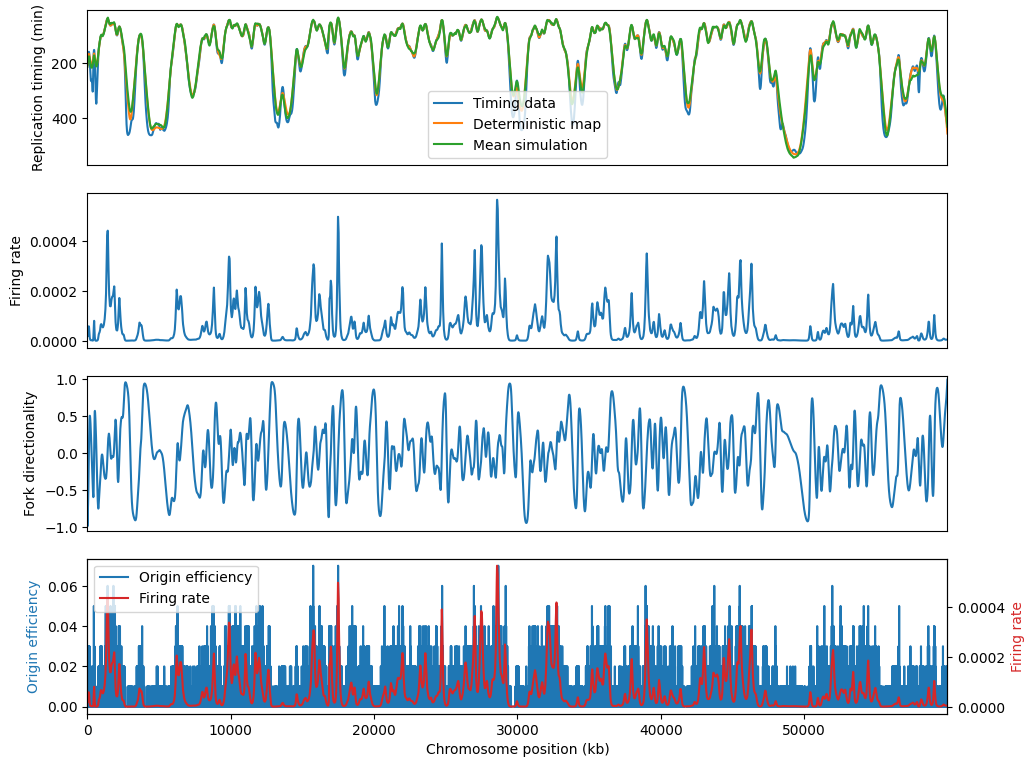

In [32]:
mplotf(
    [
        [replication_timing, replication_timing_mapped, simulation["replication_timing"]],
        firing_rate,
        fork_directionality,
        [simulation["origin_efficiency"], firing_rate],
    ],
    mlabels=[
        ["Timing data", "Deterministic map", "Mean simulation"],
        [None],
        [None],
        ["Origin efficiency", "Firing rate"],
    ],
    mx_array=[positions_kb, positions_kb, positions_kb, positions_kb],
    mdual_axis=[False, False, False, True],
    minvyQ=[True, False, False, False],
    mylims=[(None, None), (None, None), (-1.05, 1.05), (None, None)],
    mxtitle=["", "", "", "Chromosome position (kb)"],
    mytitle=[
        "Replication timing (min)",
        "Firing rate",
        "Fork directionality",
        "Simulation output",
    ],
    figsize=(10, 2.2),
    hspace=0.18,
)